# 1 · El grafo más simple

Lecciones 1 y 2 del módulo 1: [Motivación](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/57712261-lesson-1-motivation) y [El grafo más simple](https://academy.langchain.com/courses/take/intro-to-langgraph/lessons/58238187-lesson-2-simple-graph). El notebook original es [`simple-graph.ipynb`](../../langchain-academy/module-1/simple-graph.ipynb).

Este notebook no usa ningún modelo de lenguaje: el grafo solo junta texto. Así se ven las piezas de LangGraph sin nada encima. Corre sin claves y en un par de segundos.

**Qué vas a ver:** el estado, los nodos, las aristas normales y condicionales, cómo se compila un grafo y cómo seguir su ejecución paso a paso.

## Por qué un grafo

Un modelo de lenguaje, por sí solo, recibe texto y devuelve texto. Para que haga algo más hay que rodearlo de pasos: buscar información, llamar a una herramienta, revisar el resultado. Hay dos formas extremas de armar esos pasos:

| | Quién decide el paso siguiente | A favor | En contra |
|---|---|---|---|
| **Cadena** | Tú, de antemano: siempre A → B → C | Predecible | No se adapta |
| **Agente libre** | El modelo, en cada paso | Se adapta | Difícil de controlar |

LangGraph queda entre los dos. Tú dibujas el grafo: qué pasos existen y entre cuáles se puede saltar. El modelo decide solo en las bifurcaciones que dejaste. Cuanto más control necesitas, menos bifurcaciones dejas.

Encima de eso, LangGraph agrega memoria entre ejecuciones, streaming y pausas para que una persona apruebe un paso, que son los módulos 2 y 3. Aquí se parte por lo más básico.

## El estado

El estado es la información que viaja por el grafo. Cada nodo lo lee y puede cambiarlo. Se define con un `TypedDict`: un diccionario de Python con claves y tipos fijos.

In [1]:
from typing_extensions import TypedDict


class Estado(TypedDict):
    estado_grafo: str

Este estado tiene una sola clave, `estado_grafo`, que guarda un texto. Python no comprueba los tipos de un `TypedDict` al ejecutar: sirven de documentación y para que el editor avise. Lo que sí importa son los nombres de las claves, como se verá más abajo.

## Los nodos

Un nodo es una función común que recibe el estado y devuelve un diccionario con **solo las claves que quiere cambiar**. LangGraph toma ese diccionario y actualiza el estado. Por defecto, el valor nuevo reemplaza al anterior.

In [2]:
def nodo_1(estado):
    return {"estado_grafo": estado["estado_grafo"] + " Me siento"}

def nodo_2(estado):
    return {"estado_grafo": estado["estado_grafo"] + " feliz."}

def nodo_3(estado):
    return {"estado_grafo": estado["estado_grafo"] + " triste."}

Ningún nodo modifica `estado` directamente. Cada uno devuelve un valor nuevo y deja que LangGraph lo aplique. Esa separación es la que más adelante permite guardar el estado después de cada paso y volver a uno anterior.

## Las aristas

Las aristas conectan los nodos. Hay dos tipos:

- **Normal**: siempre va al mismo nodo. Por ejemplo, de `nodo_2` a `END`.
- **Condicional**: una función mira el estado y devuelve el nombre del nodo que sigue.

Esta es la función de la arista condicional. Aquí elige al azar. En un agente, la misma decisión depende de lo que respondió el modelo.

In [3]:
import random
from typing import Literal


def decidir_animo(estado) -> Literal["nodo_2", "nodo_3"]:
    if random.random() < 0.5:
        return "nodo_2"
    return "nodo_3"

El `-> Literal["nodo_2", "nodo_3"]` le dice a LangGraph a qué nodos puede llevar esta arista. Sin esa anotación el grafo funcionaría igual, pero LangGraph no sabría qué flechas dibujar.

## Armar el grafo

`StateGraph(Estado)` crea un grafo vacío con ese estado. Después se agregan los nodos, cada uno con un nombre, y las aristas entre esos nombres. `START` y `END` son dos nodos especiales: por dónde entra la ejecución y dónde termina.

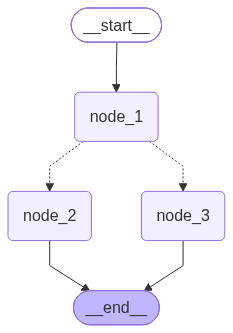

In [4]:
from IPython.display import Image, display
from langgraph.graph import StateGraph, START, END

constructor = StateGraph(Estado)
constructor.add_node("nodo_1", nodo_1)
constructor.add_node("nodo_2", nodo_2)
constructor.add_node("nodo_3", nodo_3)

constructor.add_edge(START, "nodo_1")
constructor.add_conditional_edges("nodo_1", decidir_animo)
constructor.add_edge("nodo_2", END)
constructor.add_edge("nodo_3", END)

grafo = constructor.compile()
display(Image(grafo.get_graph().draw_mermaid_png()))

`compile()` revisa que el grafo esté bien armado, por ejemplo que no haya aristas hacia nodos que no existen, y devuelve un objeto que se puede ejecutar. En el dibujo, las aristas punteadas son las condicionales.

`draw_mermaid_png()` dibuja con el servicio en línea mermaid.ink, así que necesita internet. Sin conexión, `print(grafo.get_graph().draw_mermaid())` muestra el mismo grafo como texto.

## Ejecutarlo

`invoke` recibe el estado inicial, recorre el grafo hasta `END` y devuelve el estado final.

In [5]:
grafo.invoke({"estado_grafo": "Hola, soy Benja."})

{'graph_state': 'Hola, soy Benja. I am sad!'}

Si lo ejecutas varias veces, a veces sale `feliz.` y a veces `triste.`. Para comprobar que la elección es mitad y mitad, conviene contar muchas ejecuciones:

In [6]:
from collections import Counter

random.seed(0)
Counter(grafo.invoke({"estado_grafo": ""})["estado_grafo"] for _ in range(1000))

Counter({' I am sad!': 503, ' I am happy!': 497})

## Ver cada paso con `stream`

`invoke` solo entrega el resultado final. `stream` va entregando lo que hace cada nodo a medida que se ejecuta. Con `stream_mode="updates"`, cada paso es un diccionario `{nombre del nodo: lo que devolvió}`:

In [7]:
for paso in grafo.stream({"estado_grafo": "Hola, soy Benja."}, stream_mode="updates"):
    print(paso)

{'node_1': {'graph_state': 'Hola, soy Benja. I am'}}
{'node_2': {'graph_state': 'Hola, soy Benja. I am happy!'}}


Con `stream_mode="values"`, en cambio, cada paso es el estado completo después de ese nodo:

In [8]:
for estado in grafo.stream({"estado_grafo": "Hola, soy Benja."}, stream_mode="values"):
    print(estado)

{'graph_state': 'Hola, soy Benja.'}
{'graph_state': 'Hola, soy Benja. I am'}
{'graph_state': 'Hola, soy Benja. I am sad!'}


El primer valor es el estado de entrada, antes de que corra cualquier nodo. `stream` es la base del módulo 3, donde se muestran las respuestas de un modelo a medida que se generan.

## Dos detalles que conviene saber

**Un nodo puede no cambiar nada.** Si devuelve un diccionario vacío, el estado sigue igual y el grafo continúa.

**Una clave que no está en el estado se ignora sin aviso.** Si un nodo devuelve una clave mal escrita, LangGraph no da error: simplemente la descarta. Este grafo tiene un nodo que no cambia nada y otro que escribe `estado_graf`, con una letra de menos:

In [9]:
def no_cambia_nada(estado):
    return {}

def mal_escrito(estado):
    return {"estado_graf": estado["estado_grafo"] + " ¡cambiado!"}


prueba = StateGraph(Estado)
prueba.add_node("no_cambia_nada", no_cambia_nada)
prueba.add_node("mal_escrito", mal_escrito)
prueba.add_edge(START, "no_cambia_nada")
prueba.add_edge("no_cambia_nada", "mal_escrito")
prueba.add_edge("mal_escrito", END)

prueba.compile().invoke({"estado_grafo": "Hola"})

{'graph_state': 'Hola'}

El resultado es el mismo estado de entrada. Si un nodo parece no hacer nada, lo primero es revisar que los nombres de las claves coincidan con los del estado.

## Resumen

- El **estado** es un `TypedDict` que viaja por el grafo.
- Un **nodo** es una función que recibe el estado y devuelve solo lo que cambia. El valor nuevo reemplaza al anterior.
- Una **arista normal** siempre va al mismo nodo. Una **condicional** llama a una función que elige el siguiente.
- `compile()` valida el grafo. `invoke` devuelve el estado final y `stream` muestra cada paso.

## Ejercicios

1. Agrega un `nodo_4` que sume `" más o menos."` y haz que `decidir_animo` elija entre los tres nodos con la misma probabilidad. Cuenta 3000 ejecuciones para comprobarlo.
2. Cambia `decidir_animo` para que no sea al azar: que vaya a `nodo_2` si el texto de entrada termina en `"!"` y a `nodo_3` si no.
3. Agrega una clave `pasos: int` al estado y haz que cada nodo la aumente en 1. ¿Cuánto vale al final? ¿Qué pasa si un nodo devuelve `{"pasos": 1}` en vez de sumar? El notebook 2 muestra cómo cambiar esa regla.